<img align="right" width="400" src="https://drive.google.com/thumbnail?id=1rPeHEqFWHJcauZlU82a4hXM10TUjmHxM&sz=s4000" alt="FHNW Logo">


# Hugginface Pipelines

by Fabian Märki

## Summary
The aim of this notebook is to illustrate Huggingface's [pipelines](https://huggingface.co/docs/transformers/main_classes/pipelines) which simplify many [tasks](https://huggingface.co/docs/transformers/main_classes/pipelines#transformers.pipeline.task) (for disciplines like nlp, vision etc.) to just a few lines of code (i.e. the easy way to use Transformers models for inference).

## Links

- [Huggingface pipelines](https://huggingface.co/docs/transformers/main_classes/pipelines)

This notebook contains assigments: <font color='red'>Questions are written in red.</font>

<a href="https://colab.research.google.com/github/markif/NLP_LAB_CAS/blob/master/Huggingface_Pipelines.ipynb">
  <img align="left" src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

In [1]:
%%capture

# this will take a while
!pip install timm

We need this lib for Object Detection (see below)
### !!! After installing timm you need to restart your runtime !!!

In [2]:
%%capture

!pip install transformers

In [3]:
%%capture

!pip install 'fhnw-nlp-utils>=0.11.9,<0.12.0'

from fhnw.nlp.utils.storage import download

import pandas as pd
import numpy as np

**Make sure that a GPU is available (see [here](https://www.tutorialspoint.com/google_colab/google_colab_using_free_gpu.htm))!!!**

In [4]:
from fhnw.nlp.utils.system import set_log_level
from fhnw.nlp.utils.system import system_info

set_log_level()
print(system_info())

OS name: posix
Platform name: Linux
Platform release: 6.6.122+
Python version: 3.13.15
CPU brand: Intel(R) Xeon(R) CPU @ 2.00GHz
CPU cores: 1
RAM: 12.67GB total and 11.55GB available
GPU is a Tesla T4 with 14913MB
Torch version: 2.11.0+cu128
Tensorflow version: 2.20.0


In [5]:
from fhnw.nlp.utils.transformers import get_compute_device

device = get_compute_device()
print(device)

cuda:0


## NLP: Sentiment Analysis

In [6]:
from transformers import pipeline

texts = ["Dies ist ein guter Arzt", "Dies ist ein schlechter Arzt", "Der Arzt untersucht den Patienten"]

In [7]:
sentiment_analyzer = pipeline("sentiment-analysis", device=device)

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

In [8]:
sentiments = sentiment_analyzer(texts)

print(sentiments)

[{'label': 'NEGATIVE', 'score': 0.9548130035400391}, {'label': 'NEGATIVE', 'score': 0.5888150930404663}, {'label': 'NEGATIVE', 'score': 0.9604743123054504}]


<font color='red'>**TASK: Hm, this result is not that great. Let's go to Huggingface's [model page](https://huggingface.co/models) and look for a model that is better suited for our task.**</font>

Parameters that might be important are:
- the language (german i.e. **multilingual**)
- the task (**sentiment** analysis)

Look for these components in the name of the model.

In [9]:
#sentiment_model_name = "your_model_name"

sentiment_model_name = "nlptown/bert-base-multilingual-uncased-sentiment"

In [10]:
sentiment_analyzer = pipeline("sentiment-analysis", model=sentiment_model_name, device=device)

config.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  669MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [11]:
sentiments = sentiment_analyzer(texts)

print(sentiments)

[{'label': '5 stars', 'score': 0.5351049900054932}, {'label': '1 star', 'score': 0.7070897817611694}, {'label': '4 stars', 'score': 0.35365888476371765}]


It is also possible to specify which model version to use. It can be a branch name, a tag name, or a commit id (revision can be any identifier allowed by git since huggingface uses a git-based system for storing models).

In [12]:
reversion = "edd66ab"

In [13]:
sentiment_analyzer = pipeline("sentiment-analysis", model=sentiment_model_name, revision=reversion, device=device)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  669MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [14]:
sentiments = sentiment_analyzer(texts)

print(sentiments)

[{'label': '5 stars', 'score': 0.5351049900054932}, {'label': '1 star', 'score': 0.7070897817611694}, {'label': '4 stars', 'score': 0.35365888476371765}]


Let's have a look at the model config in order to get an understanding of e.g. the label mapping.

In [15]:
print(sentiment_analyzer.model.config)

BertConfig {
  "_num_labels": 5,
  "add_cross_attention": false,
  "architectures": [
    "BertForSequenceClassification"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "directionality": "bidi",
  "dtype": "float32",
  "eos_token_id": null,
  "finetuning_task": "sentiment-analysis",
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "1 star",
    "1": "2 stars",
    "2": "3 stars",
    "3": "4 stars",
    "4": "5 stars"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "label2id": {
    "1 star": 0,
    "2 stars": 1,
    "3 stars": 2,
    "4 stars": 3,
    "5 stars": 4
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "output_past": true,
  "pad_token_id": 0,
  "pooler_fc_size": 768,
  "pooler_num_attention_heads": 12,
  "pooler_num_fc_layers": 3,
  "

## NLP: Zero-Shot Classification

Further links that might be of interesst:
- [What is Zero-Shot Classification](https://huggingface.co/tasks/zero-shot-classification)
- [Zero-Shot Text Classification](https://huggingface.co/docs/setfit/how_to/zero_shot)

In [16]:
from transformers import pipeline

zero_shot_classifier = pipeline("zero-shot-classification", device=device)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [17]:
zero_shot_sentiments = zero_shot_classifier(texts, candidate_labels=["positive", "neutral", "negative"])

print(zero_shot_sentiments)

[{'sequence': 'Dies ist ein guter Arzt', 'labels': ['positive', 'neutral', 'negative'], 'scores': [0.8260250091552734, 0.17075303196907043, 0.003222032217308879]}, {'sequence': 'Dies ist ein schlechter Arzt', 'labels': ['negative', 'positive', 'neutral'], 'scores': [0.9975566864013672, 0.0012798409443348646, 0.001163505599834025]}, {'sequence': 'Der Arzt untersucht den Patienten', 'labels': ['neutral', 'positive', 'negative'], 'scores': [0.3521837890148163, 0.3506317436695099, 0.2971844971179962]}]


## NLP: Audio Transcription

Further links that might be of interesst:
- Huggingface's [course on audio](https://huggingface.co/learn/audio-course/chapter5/introduction)
- [Whisper](https://huggingface.co/docs/transformers/model_doc/whisper)
- [Creating a Voice Assistant](https://huggingface.co/learn/audio-course/chapter7/voice-assistant) that transcribes your microphone input
- [Record Audio in a Jupyter Notebook](https://medium.com/@harrycblum/record-audio-in-a-jupyter-notebook-da08a88278bb)

In [18]:
%%capture

!apt-get update
!apt-get -y install ffmpeg

In [19]:
download("https://drive.switch.ch/index.php/s/rWX752RRlXxGxNc/download", "data/colors.mp3")
download("https://drive.switch.ch/index.php/s/LzhtTs2nNl8L8nV/download", "data/dinner.flac")
download("https://drive.switch.ch/index.php/s/YiT4MKYnAfU0epn/download", "data/dream.flac")

In [20]:
%%time
%%capture

!pip install torchaudio

CPU times: user 1.47 s, sys: 210 ms, total: 1.68 s
Wall time: 4.38 s


In [21]:
import torch
from transformers import pipeline

transcriber_model_name = "openai/whisper-tiny.en"

In [22]:
transcriber = pipeline("automatic-speech-recognition", model=transcriber_model_name, return_timestamps=True, dtype=torch.float16, device=device)

config.json:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  151MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/1.62k [00:00<?, ?B/s]

...

normalizer.json:   0%|          | 0.00/52.7k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.83k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'return_timestamps'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


In [23]:
transcription_colors = transcriber("data/colors.mp3")

print(transcription_colors)
print(transcription_colors["text"])

[transformers] Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


{'text': " colors. Red is a vibrant color. Roses are sometimes red. Blood is red. White is the color of snow. Clouds are very often white. Blue is the color of the sky and the ocean. Black isn't really a color at all. Tar is black. A crow is black. Green is is the color of grass. It is also the color of leaves on the trees in the summer. Brown is the color of dirt. Many people have brown hair. Yellow is a bright color. Most people use yellow when they draw a picture of the sun. Orange is an easy color to remember. That is because an orange is orange. Pink is the color that we dress baby girls in. We dress baby boys in blue. Purple is the color of some bilets. The Canadian flag is red and white. What color is your flag?", 'chunks': [{'timestamp': (0.0, 9.94), 'text': ' colors. Red is a vibrant color. Roses are sometimes red. Blood is red. White is the'}, {'timestamp': (9.94, 17.18), 'text': ' color of snow. Clouds are very often white. Blue is the color of the sky and the'}, {'timestamp

In [24]:
transcription_dinner = transcriber("data/dinner.flac")

print(transcription_dinner["text"])

 He hoped there would be stew for dinner, turnips and carrots and bruised potatoes and fat mutton pieces to be ladled out and thick peppered flower-fattened sauce.


In [25]:
transcription_dream = transcriber("data/dream.flac")

print(transcription_dream["text"])

 I have a dream that one day this nation will rise up and live out the true meaning of its creed.


In [26]:
transcriptions_en = [transcription_colors["text"], transcription_dinner["text"], transcription_dream["text"]]

You can swap the model with any [Whisper checkpoint](https://huggingface.co/models?other=whisper&sort=downloads) on the Hugging Face Hub (i.e. a bigger model might result in better transcripts) or use one of the [most downloaded automatic speech recognition models](https://huggingface.co/models?pipeline_tag=automatic-speech-recognition&sort=trending).

## NLP: Translation

Further links that might be of interesst:
- Huggingface's [course on translation](https://huggingface.co/learn/nlp-course/chapter7/4?fw=pt)
- [Translation task](https://huggingface.co/docs/transformers/tasks/translation)

The translation pipline got removed with transformers v5 (see [here](https://github.com/huggingface/transformers/issues/43825#issuecomment-3871470637))

Let's still try to get translation working without a LLM...

In [27]:
# from transformers import pipeline

# translator_en_de = pipeline("translation_en_to_de", device=device)

In [28]:
%%capture

!pip install sentencepiece

In [29]:
import tensorflow as tf
from transformers import MarianMTModel, MarianTokenizer

lang_from = "en"
lang_to = "de"
compute_device = "cuda:0" if tf.config.list_physical_devices("GPU") else "cpu"

orig2dest_model_name = "Helsinki-NLP/opus-mt-"+lang_from+"-"+lang_to

orig2dest_tokenizer = MarianTokenizer.from_pretrained(orig2dest_model_name)
orig2dest_model = MarianMTModel.from_pretrained(orig2dest_model_name).to(compute_device)

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/768k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/797k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  298MB            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

In [30]:
def translate(texts, num_translations = 2):
    tokenized_texts = orig2dest_tokenizer(texts, return_tensors="pt", padding=True, truncation=True).to(compute_device)

    generate_kwargs = {"num_beams": 1, "do_sample": True, "num_return_sequences": num_translations}
    tokenized_translated_texts = orig2dest_model.generate(tokenized_texts["input_ids"], attention_mask=tokenized_texts["attention_mask"], top_p=0.7, **generate_kwargs)

    translations = []
    for i, t in enumerate(tokenized_translated_texts):
        if i % num_translations == 0:
            translation_batch = []
            translations.append(translation_batch)

        translation_batch.append(orig2dest_tokenizer.decode(t, skip_special_tokens=True))

    return translations

In [31]:
transcriptions_en = ["He hoped there would be stew for dinner, turnips and carrots and bruised potatoes and fat mutton pieces to be ladled out and thick peppered flower-fattened sauce.",
"I have a dream that one day this nation will rise up and live out the true meaning of its creed."]

translations = translate(transcriptions_en)

In [32]:
print(translations)

[['Er hoffte, zum Abendessen eintopfen zu können, Rüben und Karotten und zerquetschten Kartoffeln und fetten Hammelstücken, um sich aus dem Futter zu schmoren und die dicke blumengemästete Sauce zu pfeffern.', 'Er hoffte, dass zum Abendessen Eintopf, Rüben und Karotten und gequetschte Kartoffeln und fette Hammelstücke zum Ausbacken und dicke, mit Blumen gepflückte Soße vorhanden wären.'], ['Ich habe einen Traum, dass eines Tages diese Nation aufstehen wird und die wahre Bedeutung ihres Glaubens erleben wird.', 'Ich habe einen Traum, dass eines Tages diese Nation sich erheben wird und die wahre Bedeutung ihres Glaubens zu leben.']]


## NLP: Text to Speech

Further links that might be of interesst:
- [Text to Speech Task](https://huggingface.co/docs/transformers/tasks/text-to-speech)
- [Audio Course](https://huggingface.co/learn/audio-course/chapter6/introduction)
- [How to Clone a Voice](https://github.com/myshell-ai/OpenVoice/blob/main/demo_part3.ipynb) (see also [here](https://huggingface.co/myshell-ai/OpenVoice) and [here](https://huggingface.co/microsoft/speecht5_tts))

In [33]:
from transformers import pipeline

text_to_speech = pipeline("text-to-speech", model="suno/bark-small", device=device)

config.json:   0%|          | 0.00/8.80k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.68GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.68GB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/353 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

speaker_embeddings_path.json:   0%|          | 0.00/61.1k [00:00<?, ?B/s]

In [34]:
text = "[clears throat] This is a test ... and I just took a long pause."

output = text_to_speech(text)

[transformers] Passing `generation_config` together with generation-related arguments=({'min_eos_p', 'return_dict_in_generate'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'return_dict_in_generate'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentatio

In [35]:
from IPython.display import Audio

Audio(output["audio"], rate = output["sampling_rate"])

<font color='red'>**TASK: Go to [Huggingface pipelines](https://huggingface.co/docs/transformers/main_classes/pipelines) and try a pipeline of your own interest.**</font>

## Vision: Object Detection

Further links that might be of interesst:
- [Object Detection](https://huggingface.co/docs/transformers/tasks/object_detection)

In [36]:
%%capture

# in case you did not install it before (see above - do not forget to restart your runtime)
# !pip install timm

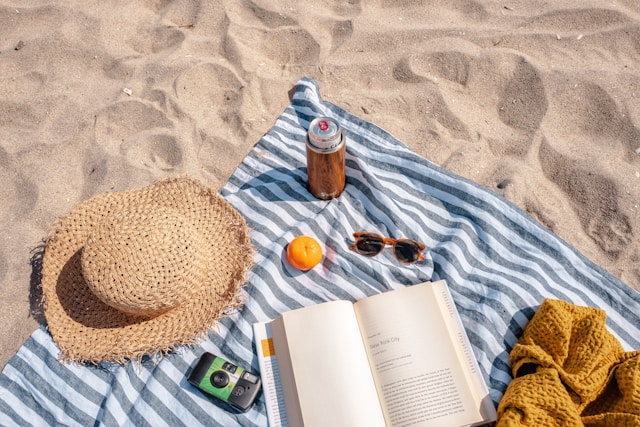

In [37]:
from transformers import pipeline
from PIL import Image, ImageDraw
from fhnw.nlp.utils.transformers import get_compute_device
from fhnw.nlp.utils.storage import download

device = get_compute_device()

download("https://drive.switch.ch/index.php/s/s2iXNIsmashuQxa/download", "data/sandy_beach.jpg")

image = Image.open("data/sandy_beach.jpg")
image

In [38]:
object_detector = pipeline("object-detection", device=device)

[transformers] No model was supplied, defaulted to facebook/detr-resnet-50 and revision 1d5f47b.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

In [39]:
detected_objects = object_detector(image)

print(detected_objects)

[{'score': 0.9821128845214844, 'label': 'bottle', 'box': {'xmin': 303, 'ymin': 119, 'xmax': 345, 'ymax': 200}}, {'score': 0.9880592226982117, 'label': 'bed', 'box': {'xmin': 0, 'ymin': 1, 'xmax': 639, 'ymax': 422}}, {'score': 0.5133408904075623, 'label': 'cell phone', 'box': {'xmin': 183, 'ymin': 351, 'xmax': 262, 'ymax': 413}}, {'score': 0.9811273217201233, 'label': 'orange', 'box': {'xmin': 286, 'ymin': 236, 'xmax': 323, 'ymax': 271}}, {'score': 0.9934751391410828, 'label': 'book', 'box': {'xmin': 252, 'ymin': 279, 'xmax': 497, 'ymax': 425}}]


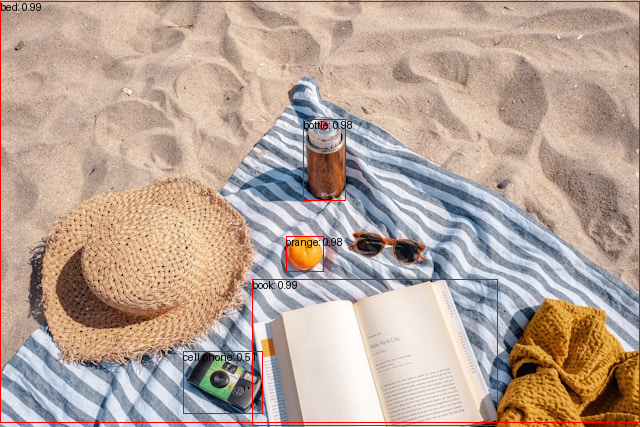

In [40]:
draw = ImageDraw.Draw(image)

for prediction in detected_objects:
    box = prediction["box"]
    label = prediction["label"]
    score = prediction["score"]

    xmin, ymin, xmax, ymax = box.values()
    draw.rectangle((xmin, ymin, xmax, ymax), outline="red", width=1)
    draw.text((xmin, ymin), f"{label}: {round(score,2)}", fill="black")

image

## Vision: Zero-Shot Object Detection

Further links that might be of interesst:
- [Zero-Shot Object Detection](https://huggingface.co/docs/transformers/tasks/zero_shot_object_detection)

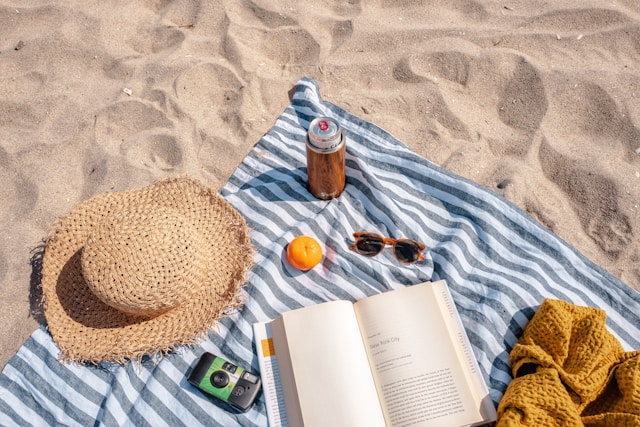

In [41]:
from transformers import pipeline
from PIL import Image, ImageDraw

download("https://drive.switch.ch/index.php/s/s2iXNIsmashuQxa/download", "data/sandy_beach.jpg")

image = Image.open("data/sandy_beach.jpg")
image

In [42]:
zero_shot_object_detector = pipeline(task="zero-shot-object-detection", model="google/owlv2-base-patch16-ensemble", device=device)

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

In [43]:
detected_objects = zero_shot_object_detector(image, candidate_labels=["hat", "book", "sunglasses", "camera"])

print(detected_objects)

[{'score': 0.6894428730010986, 'label': 'camera', 'box': {'xmin': 187, 'ymin': 352, 'xmax': 262, 'ymax': 411}}, {'score': 0.6219812035560608, 'label': 'book', 'box': {'xmin': 258, 'ymin': 279, 'xmax': 495, 'ymax': 427}}, {'score': 0.5969275832176208, 'label': 'sunglasses', 'box': {'xmin': 349, 'ymin': 232, 'xmax': 425, 'ymax': 264}}, {'score': 0.5126146078109741, 'label': 'hat', 'box': {'xmin': 39, 'ymin': 174, 'xmax': 252, 'ymax': 370}}, {'score': 0.13378974795341492, 'label': 'camera', 'box': {'xmin': 222, 'ymin': 362, 'xmax': 237, 'ymax': 374}}, {'score': 0.1095459908246994, 'label': 'hat', 'box': {'xmin': 77, 'ymin': 182, 'xmax': 238, 'ymax': 319}}]


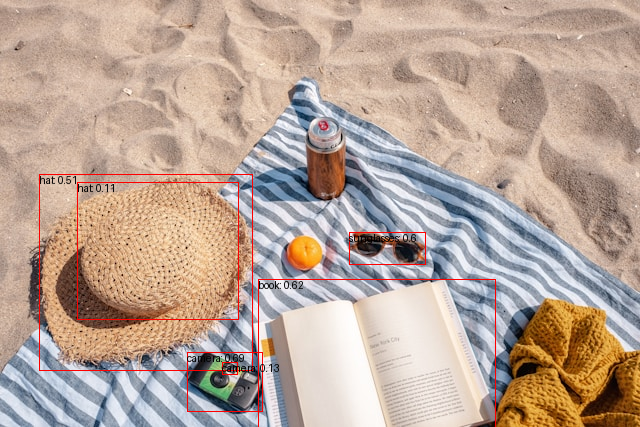

In [44]:
draw = ImageDraw.Draw(image)

for prediction in detected_objects:
    box = prediction["box"]
    label = prediction["label"]
    score = prediction["score"]

    xmin, ymin, xmax, ymax = box.values()
    draw.rectangle((xmin, ymin, xmax, ymax), outline="red", width=1)
    draw.text((xmin, ymin), f"{label}: {round(score,2)}", fill="black")

image

## Vision: Image Segmentation

Further links that might be of interesst:
- [Image Segmentation 1](https://huggingface.co/docs/transformers/main_classes/pipelines#transformers.ImageSegmentationPipeline)
- [Image Segmentation 2](https://huggingface.co/docs/transformers/main/en/tasks/semantic_segmentation)

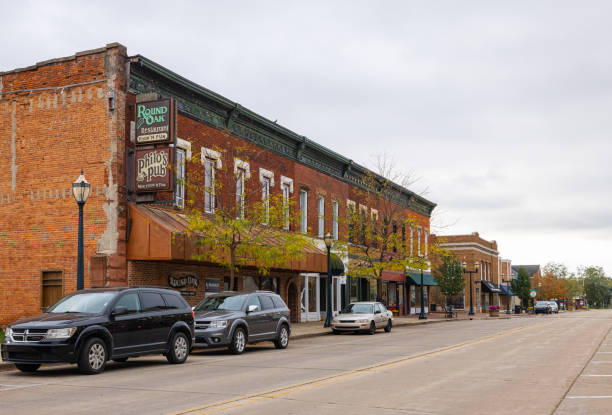

In [45]:
from transformers import pipeline
from PIL import Image

download("https://drive.switch.ch/index.php/s/Lnehm84kb1A1ekg/download", "data/cars_parking.jpg")

image = Image.open("data/cars_parking.jpg")
image

In [46]:
semantic_segmentation = pipeline("image-segmentation", "nvidia/segformer-b1-finetuned-cityscapes-1024-1024", device=device)
results = semantic_segmentation(image)
results

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.8MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 54.8MB            

model.safetensors: downloading bytes:           |  0.00B            

preprocessor_config.json:   0%|          | 0.00/273 [00:00<?, ?B/s]

[{'score': None,
  'label': 'road',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'sidewalk',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'building',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'wall',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'pole',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'traffic sign',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'vegetation',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'terrain',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'sky',
  'mask': <PIL.Image.Image image mode=L size=612x415>},
 {'score': None,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=612x415>}]

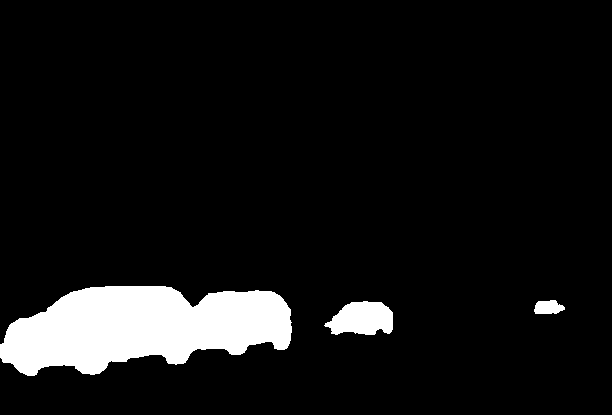

In [47]:
results[-1]["mask"]